# 定义state
## 方式1：typedDict,方式2：pydantic第三方库，需要单独安装，提供运行时数据验证和序列化功能

In [10]:
 from langchain_core.messages import AnyMessage
 from typing_extensions import TypedDict

 #定义节点间通讯的消息格式
 class State(TypedDict,total=False):
     messages:list[AnyMessage]
     extra_field:int

# 定义节点

In [11]:
from langchain_core.messages import AIMessage

def node(state: State):
    messages = state["messages"]
    new_message = AIMessage("你好，我是节点1")
    return{
        "messages":messages+[new_message],
        "extra_field":1
    }

# 创建图
## 包含一个节点，使用state通信

In [12]:
from langgraph.graph import StateGraph

graph = StateGraph(State)
graph.add_node(node)
graph.set_entry_point("node")  #设置入口名字
graph_builder = graph.compile()

# 产看节点与图结构
## 使用mermaid

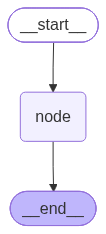

In [4]:
from IPython.display import display,Image
display(Image(graph_builder.get_graph().draw_mermaid_png()))

# 调用

In [13]:
from langchain_core.messages import HumanMessage
result = graph_builder.invoke({
    "messages":[HumanMessage("你好，我是tomie!")],
     "extra_field": 0
})
result

{'messages': [HumanMessage(content='你好，我是tomie!', additional_kwargs={}, response_metadata={}),
  AIMessage(content='你好，我是节点1', additional_kwargs={}, response_metadata={}, tool_calls=[], invalid_tool_calls=[])],
 'extra_field': 1}

# 串行控制

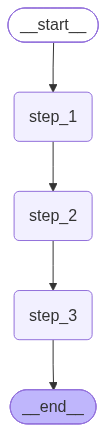

In [20]:
from typing_extensions import TypedDict
from IPython.display import Image,display
from langgraph.graph import StateGraph,START

class State(TypedDict):
    value_1:str
    value_2:str

def step_1(state: State):
    return{"value_1":"a"}
def step_2(state: State):
    current_value_1 = state["value_1"]
    return {"value_1":f"{current_value_1}+b"}
def step_3(state: State):
    return {"value_2":10}

graph_builder = StateGraph(State)
graph_builder.add_node(step_1)
graph_builder.add_node(step_2)
graph_builder.add_node(step_3)

graph_builder.add_edge(START,"step_1")
graph_builder.add_edge("step_1","step_2")
graph_builder.add_edge("step_2","step_3")

graph = graph_builder.compile()
display(Image(graph.get_graph().draw_mermaid_png()))



In [21]:
graph.invoke({"value_1":"c"})

{'value_1': 'a+b', 'value_2': 10}

# 分支控制

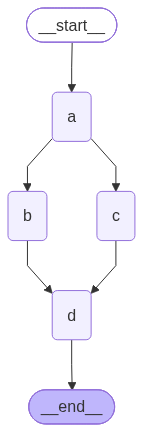

In [27]:
import operator
from typing import Any,Annotated
from typing_extensions import TypedDict
from langgraph.graph import StateGraph,START,END
from IPython.display import Image,display

# Annotataed 允许使用类型提供额外的元数据，而不影响类型检查起对类型本身的理解
class State(TypedDict):
    aggregate:Annotated[list,operator.add]

def a(state: State):
    print(f"添加A到{state['aggregate']}")
    return {"aggregate":["A"]}

def b(state: State):
    print(f"添加B到{state['aggregate']}")
    return {"aggregate":["B"]}

def c(state: State):
    print(f"添加C到{state['aggregate']}")
    return {"aggregate":["C"]}

def d(state: State):
    print(f"添加D到{state['aggregate']}")
    return {"aggregate":["D"]}
builder = StateGraph(State)
builder.add_node(a)
builder.add_node(b)
builder.add_node(c)
builder.add_node(d)

builder.add_edge(START,"a")
builder.add_edge("a","b")
builder.add_edge("a","c")
builder.add_edge("b","d")
builder.add_edge("c","d")

graph = builder.compile()
display(Image(graph.get_graph().draw_mermaid_png()))